## Step 8.2 — Fit Models on Full Development Data

Fit Logistic Regression, Random Forest and tuned XGBoost using the complete development dataset.

These fitted models will be used for calibration analysis. The locked test dataset will remain untouched.


In [20]:
import sys
from pathlib import Path

import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RANDOM_SEED, TARGET_COL
from src.preprocessing import make_pipeline

In [21]:
dev = pd.read_csv(PROJECT_ROOT / "data" / "dev.csv")

y_dev = dev[TARGET_COL]
X_dev = dev.drop(columns=[TARGET_COL])

print("Development dataset:", X_dev.shape)
print("Target:", y_dev.shape)
print("Default rate:", y_dev.mean())

Development dataset: (120000, 10)
Target: (120000,)
Default rate: 0.06684166666666666


In [22]:
# 1. Logistic Regression
lr_pipe = make_pipeline(
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_SEED
    ),
    scale=True
)


# 2. Random Forest
rf_pipe = make_pipeline(
    RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_SEED,
        n_jobs=-1
    ),
    scale=False
)


# 3. Tuned XGBoost
spw = (y_dev == 0).sum() / (y_dev == 1).sum()

xgb_pipe = make_pipeline(
    XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=1.0,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=spw,
        random_state=RANDOM_SEED,
        n_jobs=-1
    ),
    scale=False
)

In [23]:
print("Fitting Logistic Regression...")
lr_pipe.fit(X_dev, y_dev)

print("Fitting Random Forest...")
rf_pipe.fit(X_dev, y_dev)

print("Fitting Tuned XGBoost...")
xgb_pipe.fit(X_dev, y_dev)

print("\nAll three models fitted successfully!")

Fitting Logistic Regression...
Fitting Random Forest...
Fitting Tuned XGBoost...

All three models fitted successfully!


In [24]:
models = {
    "Logistic Regression": lr_pipe,
    "Random Forest": rf_pipe,
    "Tuned XGBoost": xgb_pipe
}

for name, model in models.items():
    probabilities = model.predict_proba(X_dev)[:, 1]

    print(
        f"{name}: "
        f"{len(probabilities)} predictions generated"
    )

Logistic Regression: 120000 predictions generated
Random Forest: 120000 predictions generated
Tuned XGBoost: 120000 predictions generated


## Step 8.3 — Calibration Curves

Generate reliability curves for Logistic Regression, Random Forest and Tuned XGBoost.

Compare predicted probabilities with the observed fraction of positive outcomes.

In [25]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

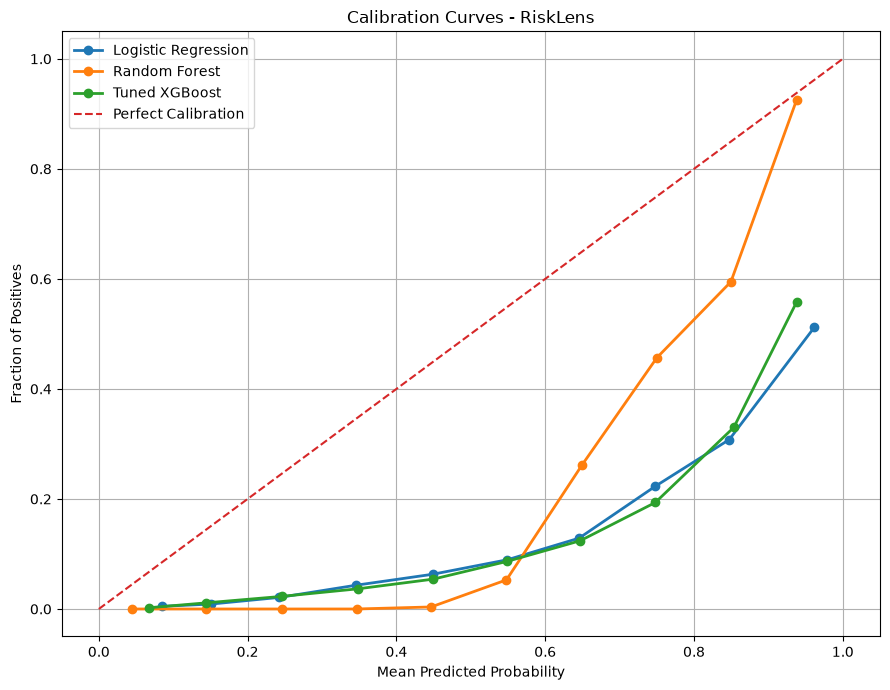

In [26]:
plt.figure(figsize=(9, 7))

for name, model in models.items():

    y_prob = model.predict_proba(X_dev)[:, 1]

    fraction_positive, mean_predicted = calibration_curve(
        y_dev,
        y_prob,
        n_bins=10,
        strategy="uniform"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        linewidth=2,
        label=name
    )

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curves - RiskLens")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.calibration import CalibratedClassifierCV

In [28]:
calibrated_rf = CalibratedClassifierCV(
    estimator=rf_pipe,
    method="isotonic",
    cv=5
)

calibrated_xgb = CalibratedClassifierCV(
    estimator=xgb_pipe,
    method="isotonic",
    cv=5
)

In [29]:
calibrated_rf.fit(X_dev, y_dev)
calibrated_xgb.fit(X_dev, y_dev)

print("Both calibrated models fitted successfully.")

Both calibrated models fitted successfully.


In [30]:
rf_calibrated_probs = calibrated_rf.predict_proba(X_dev)[:, 1]

xgb_calibrated_probs = calibrated_xgb.predict_proba(X_dev)[:, 1]

print("Random Forest calibrated predictions:", len(rf_calibrated_probs))
print("XGBoost calibrated predictions:", len(xgb_calibrated_probs))

Random Forest calibrated predictions: 120000
XGBoost calibrated predictions: 120000


In [31]:
rf_probs = rf_pipe.predict_proba(X_dev)[:, 1]

xgb_probs = xgb_pipe.predict_proba(X_dev)[:, 1]

print("Original probabilities generated.")

Original probabilities generated.


In [32]:
from sklearn.metrics import brier_score_loss

print("Random Forest:")
print("Before:", brier_score_loss(y_dev, rf_probs))
print("After:", brier_score_loss(y_dev, rf_calibrated_probs))

print("\nXGBoost:")
print("Before:", brier_score_loss(y_dev, xgb_probs))
print("After:", brier_score_loss(y_dev, xgb_calibrated_probs))

Random Forest:
Before: 0.07144690930959188
After: 0.03332985538512922

XGBoost:
Before: 0.13852836191654205
After: 0.04759274441538637


In [33]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import brier_score_loss

# Uncalibrated out-of-fold predictions
rf_oof = cross_val_predict(
    rf_pipe, X_dev, y_dev,
    cv=5,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

xgb_oof = cross_val_predict(
    xgb_pipe, X_dev, y_dev,
    cv=5,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Calibrated out-of-fold predictions
rf_cal_oof = cross_val_predict(
    calibrated_rf, X_dev, y_dev,
    cv=5,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

xgb_cal_oof = cross_val_predict(
    calibrated_xgb, X_dev, y_dev,
    cv=5,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Random Forest:")
print("Before:", brier_score_loss(y_dev, rf_oof))
print("After:", brier_score_loss(y_dev, rf_cal_oof))

print("\nXGBoost:")
print("Before:", brier_score_loss(y_dev, xgb_oof))
print("After:", brier_score_loss(y_dev, xgb_cal_oof))

Random Forest:
Before: 0.09592507710207478
After: 0.04956315564150904

XGBoost:
Before: 0.13947805762290955
After: 0.04902939817039233


### Step 8.4 — Tree Model Calibration Results

Isotonic calibration was applied to Random Forest and XGBoost using 5-fold cross-validation.

Out-of-fold predictions were used to compare the Brier scores before and after calibration.

**Results:**

| Model         | Brier Before | Brier After |
| ------------- | -----------: | ----------: |
| Random Forest |     0.095925 |    0.049563 |
| XGBoost       |     0.139478 |    0.049029 |

**Observations:**

1. Calibration substantially reduced the Brier score for both tree-based models.
2. Calibrated XGBoost achieved the lowest Brier score.
3. Calibrated Random Forest also achieved a very similar Brier score.
4. Isotonic calibration improved the quality of predicted probabilities on the development data.

**Conclusion:**

Calibration is beneficial for both Random Forest and XGBoost based on the out-of-fold Brier score comparison. Both calibrated models will be considered in the subsequent model-selection process.


### Step 8.5 — Calibration Findings

The Random Forest and XGBoost models were evaluated before and after isotonic calibration using out-of-fold predictions.

**Key findings:**

1. Random Forest's Brier score improved from 0.095925 to 0.049563.
2. XGBoost's Brier score improved from 0.139478 to 0.049029.
3. Calibrated XGBoost achieved the lowest Brier score among the two calibrated models.
4. Both models showed substantial improvements in probability calibration.

**Conclusion:**

Isotonic calibration substantially improved the Brier scores of both tree-based models. Calibrated Random Forest and XGBoost will be considered during final model selection.


In [34]:
from sklearn.model_selection import cross_val_predict

lr_oof = cross_val_predict(
    lr_pipe,
    X_dev,
    y_dev,
    cv=5,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

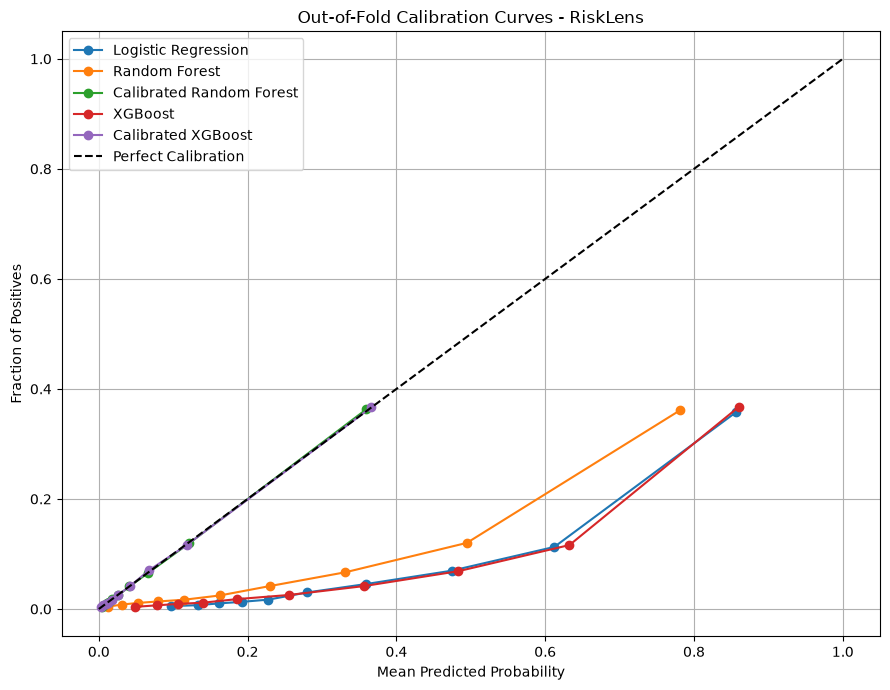

In [35]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from pathlib import Path

models_for_plot = {
    "Logistic Regression": lr_oof,
    "Random Forest": rf_oof,
    "Calibrated Random Forest": rf_cal_oof,
    "XGBoost": xgb_oof,
    "Calibrated XGBoost": xgb_cal_oof
}

plt.figure(figsize=(9, 7))

for name, probabilities in models_for_plot.items():
    fraction_positive, mean_predicted = calibration_curve(
        y_dev,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=name
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Out-of-Fold Calibration Curves - RiskLens")
plt.legend()
plt.grid(True)
plt.tight_layout()

Path("../figures").mkdir(exist_ok=True)

plt.savefig(
    "../figures/calibration_curves_oof.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
print(Path("../figures/calibration_curves_oof.png").exists())

True
